# Test Data Distribution

This notebook summarises the manually labelled test datasets by airport and season.

In [9]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


PROJECT_ROOT = Path.home() / "Projects" / "OSN_pushback_detection"
LABELED_ROOT = PROJECT_ROOT / "data" / "test" / "02_labeled"

SEASON_ORDER = ["Spring", "Summer", "Autumn", "Winter"]


## Load datasets

In [10]:
def read_annotations(directory: Path) -> pd.DataFrame:
    csv_path = directory / "annotations.csv"
    json_path = directory / "annotations.json"

    if csv_path.exists():
        return pd.read_csv(csv_path)

    if json_path.exists():
        content = json.loads(json_path.read_text(encoding="utf-8"))

        if isinstance(content, list):
            return pd.DataFrame(content)

        if isinstance(content, dict):
            for key in ("annotations", "labels", "records", "data"):
                if isinstance(content.get(key), list):
                    return pd.DataFrame(content[key])

    raise FileNotFoundError(f"No annotations found in {directory}")


rows = []

for airport_dir in sorted(
    path for path in LABELED_ROOT.iterdir()
    if path.is_dir()
):
    airport = airport_dir.name

    for season in SEASON_ORDER:
        season_dir = airport_dir / season

        if not season_dir.exists():
            continue

        for date_dir in sorted(
            path for path in season_dir.iterdir()
            if path.is_dir()
        ):
            annotations = read_annotations(date_dir)

            rows.append(
                {
                    "airport": airport,
                    "season": season,
                    "date": pd.to_datetime(
                        date_dir.name,
                        format="%d-%m-%y",
                    ),
                    "total": annotations["flight_id"]
                    .dropna()
                    .astype(str)
                    .nunique(),
                }
            )


datasets = (
    pd.DataFrame(rows)
    .sort_values(["airport", "date"])
    .reset_index(drop=True)
)

datasets


,airport,season,date,total
0,EBBR,Spring,2025-04-18,233
1,EBBR,Summer,2025-07-17,276
2,EBBR,Autumn,2025-11-05,223
3,EBBR,Winter,2025-12-05,236
4,KBOS,Winter,2025-02-08,235
5,KBOS,Autumn,2025-10-18,271
6,KBOS,Spring,2026-03-17,231
7,KBOS,Spring,2026-05-25,392
8,SABE,Winter,2025-01-14,140
9,SABE,Spring,2025-03-11,127


## Summary

In [11]:
summary_rows = []

for airport in sorted(datasets["airport"].unique()):
    for season in SEASON_ORDER:
        selected = datasets.loc[
            datasets["airport"].eq(airport)
            & datasets["season"].eq(season)
        ].sort_values("date")

        summary_rows.append(
            {
                "airport": airport,
                "season": season,
                "dates": (
                    " | ".join(
                        selected["date"].dt.strftime("%d %b %Y")
                    )
                    if not selected.empty
                    else "--"
                ),
                "total": (
                    int(selected["total"].sum())
                    if not selected.empty
                    else np.nan
                ),
            }
        )

summary = pd.DataFrame(summary_rows)
summary


,airport,season,dates,total
0,EBBR,Spring,18 Apr 2025,233.0
1,EBBR,Summer,17 Jul 2025,276.0
2,EBBR,Autumn,05 Nov 2025,223.0
3,EBBR,Winter,05 Dec 2025,236.0
4,KBOS,Spring,17 Mar 2026 | 25 May 2026,623.0
5,KBOS,Summer,--,NaN
6,KBOS,Autumn,18 Oct 2025,271.0
7,KBOS,Winter,08 Feb 2025,235.0
8,SABE,Spring,11 Mar 2025 | 27 Apr 2025,257.0
9,SABE,Summer,08 Aug 2025 | 04 Jun 2026,272.0


## Plot

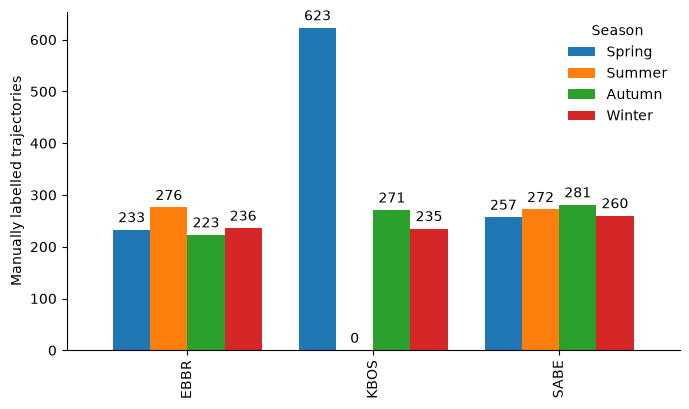

In [12]:
plot_data = (
    summary
    .pivot(
        index="airport",
        columns="season",
        values="total",
    )
    .reindex(columns=SEASON_ORDER)
)

ax = plot_data.plot(
    kind="bar",
    figsize=(7.0, 4.2),
    width=0.8,
)

ax.set_xlabel("")
ax.set_ylabel("Manually labelled trajectories")
ax.legend(title="Season", frameon=False)

for container in ax.containers:
    labels = [
        f"{bar.get_height():.0f}"
        if np.isfinite(bar.get_height())
        else ""
        for bar in container
    ]
    ax.bar_label(container, labels=labels, padding=3)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()
